# Countries data analysis
-Explore the dataframe

In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
from matplotlib import pyplot as plt

df_countries = pd.read_csv('../data/countries.csv')
df_countries.head()

In [169]:
df_countries.shape

(693476, 2)

In [170]:
df_countries.columns

Index(['id', 'country'], dtype='object')

In [171]:
df_countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693476 entries, 0 to 693475
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   id       693476 non-null  int64 
 1   country  693476 non-null  object
dtypes: int64(1), object(1)
memory usage: 10.6+ MB


In [172]:
df_countries.describe()

,id
count,6.934760e+05
mean,1.388132e+06
std,2.691242e+05
min,1.000001e+06
25%,1.148019e+06
50%,1.352616e+06
75%,1.606962e+06
max,1.941597e+06


In [173]:
df_countries.dtypes

id          int64
country    object
dtype: object

In [174]:
df_countries['country'] = df_countries['country'].astype('string')
df_countries.dtypes

id                  int64
country    string[python]
dtype: object

In [175]:
df_countries.isna().sum()

id         0
country    0
dtype: int64

In [176]:
df_countries.groupby('country').describe()

id                                                      \
                 count          mean            std        min         25%   
country                                                                      
Afghanistan      212.0  1.419005e+06  252397.304557  1012854.0  1197014.00   
Albania          390.0  1.391216e+06  187148.618221  1007461.0  1261714.50   
Algeria          513.0  1.453757e+06  283025.446463  1002039.0  1194591.00   
American Samoa     6.0  1.285736e+06  140228.202062  1088155.0  1179176.25   
Andorra           25.0  1.249493e+06  137871.486451  1059366.0  1138829.00   
...                ...           ...            ...        ...         ...   
Western Sahara     5.0  1.284202e+06  242961.440518  1084526.0  1119703.00   
Yemen             26.0  1.255615e+06  169456.548989  1042236.0  1122059.00   
Yugoslavia      2411.0  1.417121e+06  243894.540594  1003815.0  1207155.50   
Zambia            40.0  1.487076e+06  264805.211248  1007244.0  1252196.50   
Zimbabwe          66.0  1.352050e+06  225785.477554  1012779.0  1155139.75   

                                                  
                      50%         75%        max  
country                                           
Afghanistan     1418843.0  1623735.50  1936883.0  
Albania         1385777.5  1523552.75  1843479.0  
Algeria         1430519.0  1747544.00  1940646.0  
American Samoa  1335723.0  1388846.25  1421265.0  
Andorra         1272609.0  1350267.00  1571345.0  
...                   ...         ...        ...  
Western Sahara  1133666.0  1457693.00  1625421.0  
Yemen           1211152.5  1391976.00  1606919.0  
Yugoslavia      1388872.0  1613747.50  1937311.0  
Zambia          1495938.0  1748387.75  1843990.0  
Zimbabwe        1343589.0  1503091.75  1902173.0  

[247 rows x 8 columns]

In [177]:
df_countries = df_countries.groupby('country')['id'].nunique().reset_index(name='movie_count')
df_countries

,country,movie_count
0,Afghanistan,212
1,Albania,390
2,Algeria,513
3,American Samoa,6
4,Andorra,25
...,...,...
242,Western Sahara,5
243,Yemen,26
244,Yugoslavia,2411
245,Zambia,40


- Ambiguous country names, let's check if there are any duplicates or similar names

In [178]:
print("US?", df_countries['country'].eq("US").sum())
print("USA?", df_countries['country'].eq("USA").sum())
print("United States?", df_countries['country'].eq("United States").sum())
print("Uk?", df_countries['country'].eq("Uk").sum())
print("Russian Federation?", df_countries['country'].eq("Russian Federation").sum())

df_countries['country'] = df_countries['country'].replace({
    'US': 'United States of America',
    'USA': 'United States of America',
    'United States': 'United States of America',
    'Uk': 'United Kingdom',
    'Russian Federation': 'Russia',
    'Congo': 'Republic of the Congo',
    'Democratic Republic of Congo': 'Democratic Republic of the Congo',

})

print(df_countries)

US? 0
USA? 1
United States? 0
Uk? 0
Russian Federation? 1
            country  movie_count
0       Afghanistan          212
1           Albania          390
2           Algeria          513
3    American Samoa            6
4           Andorra           25
..              ...          ...
242  Western Sahara            5
243           Yemen           26
244      Yugoslavia         2411
245          Zambia           40
246        Zimbabwe           66

[247 rows x 2 columns]


- loading the world map

In [179]:
world = gpd.read_file('https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip')

world.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


- merge the dataframe with the world map

In [180]:
world_data_gdf = world.merge(df_countries, how='left', left_on='SOVEREIGNT', right_on='country')
world_data_gdf.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry,country,movie_count
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ...",Fiji,24.0
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...",United Republic of Tanzania,92.0
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948...",Western Sahara,5.0
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",Canada,23054.0
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312...",United States of America,174489.0


- display the world map with the number of movies for each country

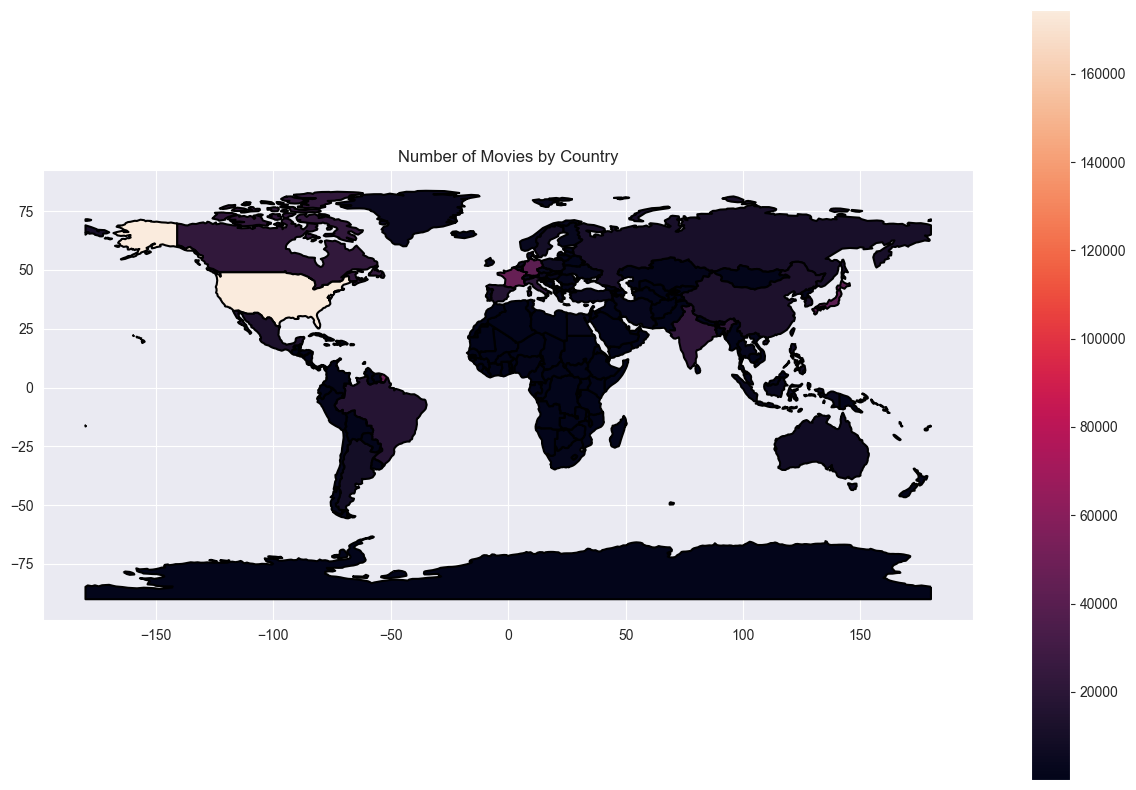

In [181]:
world_data_gdf.plot(figsize=(15,10), edgecolor='black', linewidth=1.5, column='movie_count', legend=True)
plt.title('Number of Movies by Country')
plt.show()

In [182]:
df_countries.loc[df_countries['country'].str.contains('Congo')]

#world_data_gdf.loc[world_data_gdf['SOVEREIGNT'].str.contains('Congo')]

,country,movie_count
50,Republic of the Congo,32
58,Democratic Republic of the Congo,128


- display the world map with the number of movies for each continent

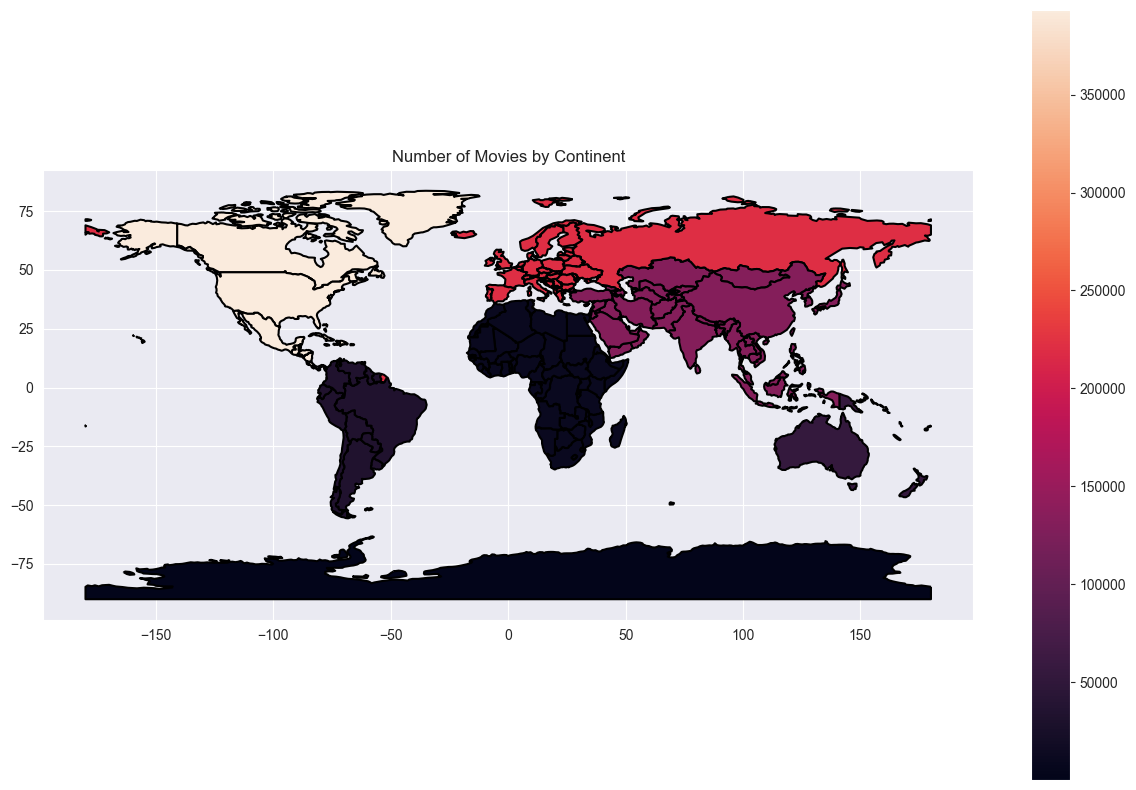

In [183]:
world['continent'] = world['CONTINENT']
world_data_gdf = world.merge(df_countries, how='left', left_on='SOVEREIGNT', right_on='country')
continent_data = world_data_gdf.groupby('continent')['movie_count'].sum().reset_index()


world_continent_gdf = world.merge(continent_data, how='left', on='continent')


world_continent_gdf.plot(figsize=(15, 10), edgecolor='black', linewidth=1.5, column='movie_count', legend=True )
plt.title('Number of Movies by Continent')
plt.show()